
## 1. Import Libraries and Load the Dataset

In this section, we import the required Python libraries and load
the Iris flower dataset provided by scikit-learn.

In [1]:

# Import pandas for working with tables of data
import pandas as pd

# Import the built-in Iris dataset
from sklearn.datasets import load_iris

# Import matplotlib for creating graphs
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Load the Iris dataset
iris = load_iris()

# Display the available feature names
print("Feature names:")
print(iris.feature_names)

# Display the species names
print("\nSpecies names:")
print(iris.target_names)

# Display the number of flowers
print("\nTotal number of flowers:", len(iris.data))

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Species names:
['setosa' 'versicolor' 'virginica']

Total number of flowers: 150


In [3]:

# Create a table containing the flower measurements
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the correct species name for each flower
df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset,
identify data quality issues, and discover patterns before
building machine learning models.

In [4]:

# Display the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (150, 5)


In [5]:

# Display column names, data types, and non-missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB


In [6]:

# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [7]:

# Display descriptive statistics for numerical columns
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:

# Count the number of flowers belonging to each species
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 3. Data Visualization

Visualize the Iris dataset to understand feature distributions,
relationships between measurements, and differences among species.

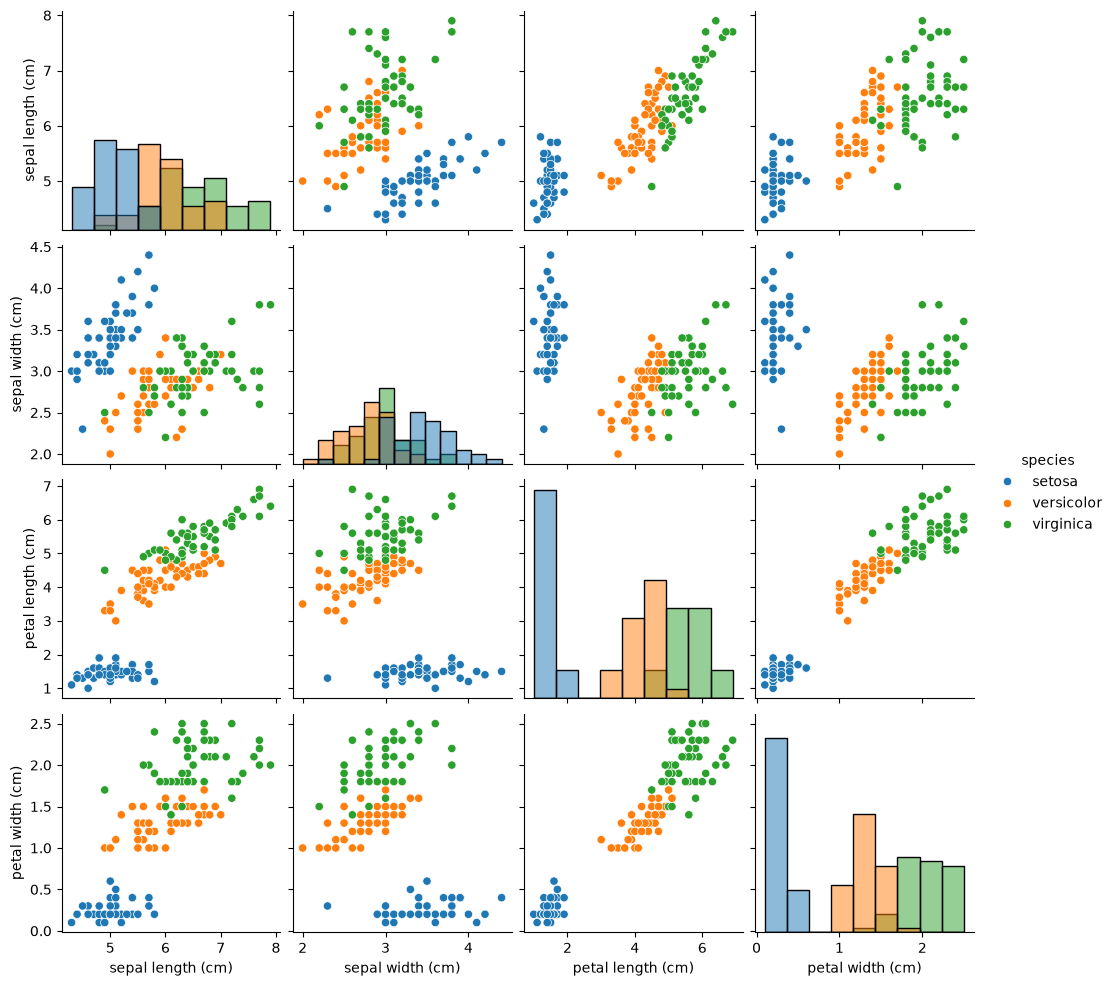

In [9]:

# Create a pairplot to compare all numerical features
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

# Display the plot
plt.show()

### 3.1 Box Plots for Feature Distributions

Compare the distribution of each measurement across the three
Iris species using box plots.

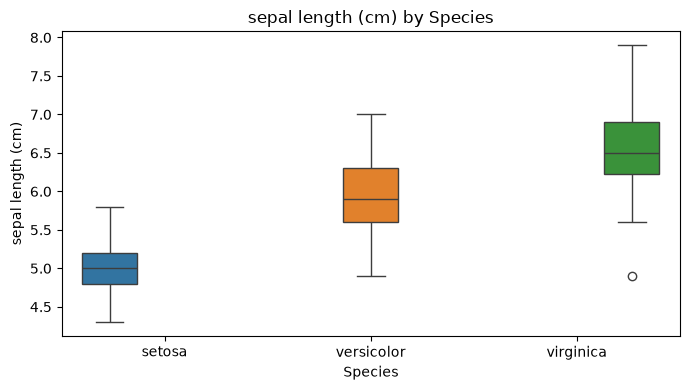

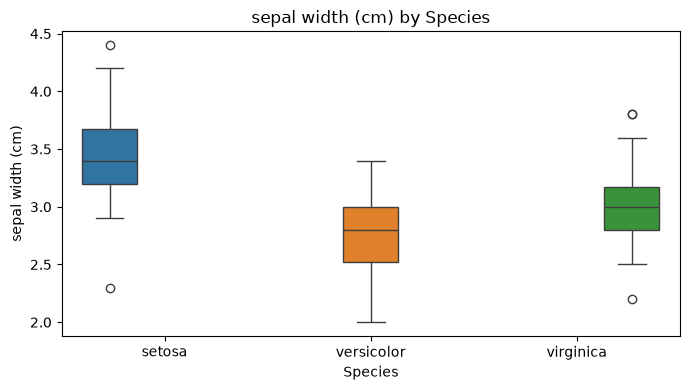

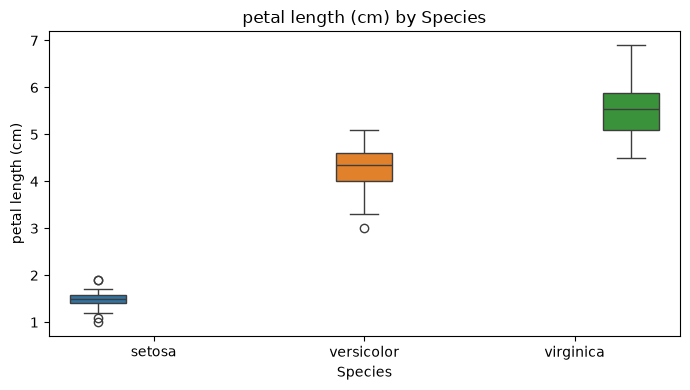

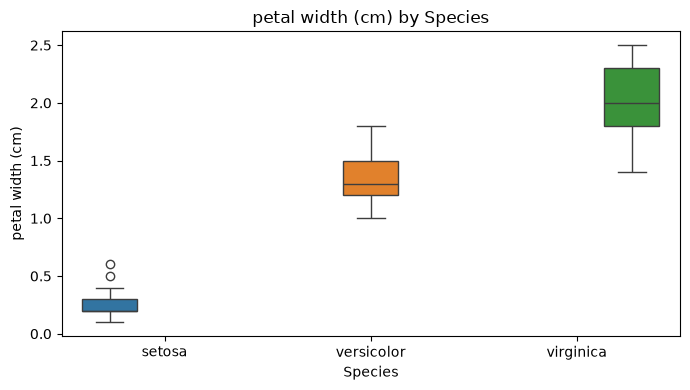

In [10]:

# List the four numerical features
features = iris.feature_names

# Create one box plot for each feature
for feature in features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        hue="species",
        legend=False
    )

    plt.title(f"{feature} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

### 3.2 Initial Feature Selection Observations

The pairplot and box plots help compare the four measurements
across the three Iris species.

Petal length and petal width appear particularly useful for
distinguishing the species because their distributions show
clearer separation. Sepal measurements show greater overlap.

These are visual observations. Model evaluation will provide
additional evidence about the usefulness of the features.


## 4. Data Preparation and Train-Test Split

Separate the flower measurements into features (X) and target labels (y).
Split the dataset into training and testing sets using an 80:20 ratio.
Stratify the split to preserve the proportion of each species.

In [11]:

# X contains the input measurements
X = df.drop("species", axis=1)

# y contains the correct species labels
y = df["species"]

# Display the dimensions of X and y
print("Feature data shape:", X.shape)
print("Target data shape:", y.shape)

Feature data shape: (150, 4)
Target data shape: (150,)


In [12]:

# Import the function used to split the dataset
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)


In [13]:

# Check the species distribution in the training set
print("Training species counts:")
print(y_train.value_counts())

# Check the species distribution in the testing set
print("\nTesting species counts:")
print(y_test.value_counts())

Training species counts:
species
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64

Testing species counts:
species
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64


## 5. Model Training

Train two classification models: Logistic Regression and K-Nearest Neighbours (KNN).

A machine learning model learns patterns from the training data and uses those patterns to predict the species of unseen flowers.

Feature scaling is applied because the models can perform better when numerical features are on comparable scales.


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

print("Model training tools imported successfully!")

Model training tools imported successfully!


In [15]:
# Create the Logistic Regression pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
# Create the KNN pipeline
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


## 6. Model Evaluation

Evaluate the trained Logistic Regression and K-Nearest Neighbours models using the unseen test dataset.

The evaluation includes accuracy, a confusion matrix, precision, recall, and F1-score to understand how well each model classifies the Iris species.


In [17]:
# Predict species using both trained models
logistic_predictions = logistic_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)

print("Logistic Regression predictions:")
print(logistic_predictions)

print("\nKNN predictions:")
print(knn_predictions)

Logistic Regression predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

KNN predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


In [18]:
from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(y_test, logistic_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.2%}")
print(f"KNN Accuracy: {knn_accuracy:.2%}")

Logistic Regression Accuracy: 93.33%
KNN Accuracy: 93.33%


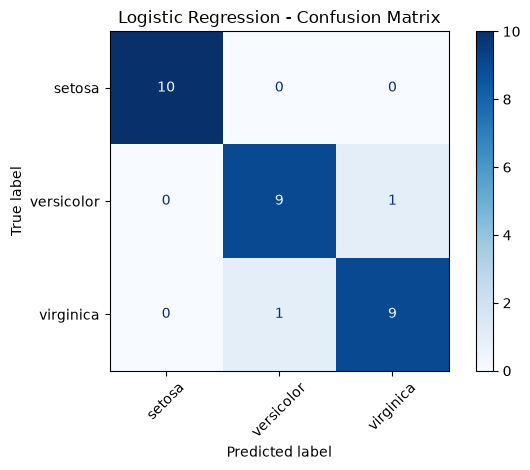

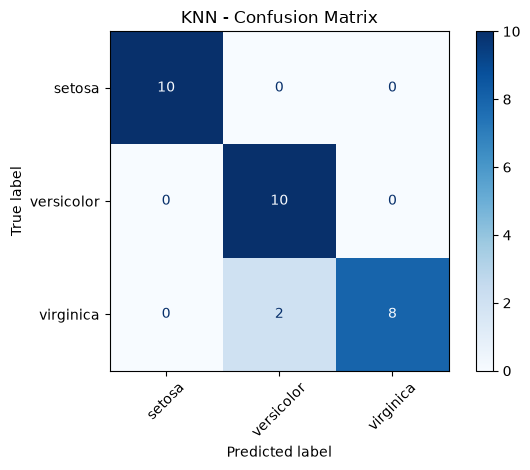

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrix for Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=iris.target_names,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Confusion matrix for KNN
ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    labels=iris.target_names,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import classification_report

print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=iris.target_names
))

print("\nKNN CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    knn_predictions,
    target_names=iris.target_names
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


KNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



### 6.1 Model Comparison and Selection

Both Logistic Regression and K-Nearest Neighbours achieved an accuracy of 93.33% on the test dataset, correctly classifying 28 out of 30 flowers.

Both models classified Setosa perfectly. Logistic Regression achieved better recall for Virginica, while KNN achieved slightly better recall for Versicolor and slightly higher macro precision.

Based on these results, Logistic Regression is selected as the preferred model for this experiment because of its more balanced performance across Versicolor and Virginica. However, the difference is small, and further validation on different data splits would help confirm the selection.


## 7. Conclusion

The Iris Flower Classification project successfully demonstrates how machine learning can classify iris flowers into Setosa, Versicolor, and Virginica using sepal and petal measurements.

Exploratory Data Analysis revealed that petal length and petal width are useful features for distinguishing the species.

Two classification algorithms, Logistic Regression and K-Nearest Neighbours (KNN), were trained and evaluated. Both achieved 93.33% test accuracy, correctly classifying 28 out of 30 test samples.

Logistic Regression was selected as the preferred model for this experiment based on its performance across the species. However, further testing on different data splits would help establish whether this advantage is consistent.

### Limitations

* Evaluation used a single train-test split of 150 samples.
* The results may vary with different training and testing samples.
* Further validation is needed before generalising performance to new datasets.


## 8. Project Summary

* **Dataset:** Iris dataset from scikit-learn
* **Total samples:** 150
* **Features:** 4 numerical flower measurements
* **Classes:** Setosa, Versicolor, Virginica
* **Models:** Logistic Regression and K-Nearest Neighbours
* **Test split:** 20%
* **Best observed test accuracy:** 93.33%
* **Libraries:** Python, pandas, scikit-learn, Matplotlib, Seaborn
